# STAT 8810 Project — Part 1: Propensity score estimation

Three propensity score models are compared on the simulated data from `01_generate_data.ipynb`:

| Model | Type | Hyperparameter tuning |
|---|---|---|
| Logistic regression | baseline (main effects only, unpenalized MLE) | none |
| MLP | deep learning (PyTorch) | early stopping on an inner validation split |
| Gradient boosting | machine learning (scikit-learn) | early stopping on an inner validation split |

All three are trained with the **same binary cross-entropy (log-likelihood) loss**; they differ only in the function class used for $\mathrm{logit}\, e(X)$.

**Hyperparameters** (fixed for all replications) were chosen on 10 pilot datasets per scenario, generated with a different seed and not used in any reported result:
- MLP: 10 → 32 → 32 → 1, ReLU, dropout 0.2, Adam (lr $10^{-3}$, weight decay $10^{-2}$), batch 64, early stopping with patience 50 (max 500 epochs). Weight decay $10^{-2}$ instead of $10^{-3}$ lowered the pilot MSE by about 10–15% and removed most very early stops (best epoch < 10).
- Boosting: depth-2 trees, learning rate 0.05, min 20 samples per leaf, L2 = 1, early stopping with patience 20 (max 1000 trees). Depth 2 had slightly lower pilot MSE than depth 3 or 4.

## 5-fold cross-fitting

For each scenario and each replication $r = 1,\dots,50$ (one dataset with $n = 1000$):

1. **Split.** Randomly assign the 1000 units to $K = 5$ folds of 200, stratified on $A$ so every fold has about the same treated share. The same split is used for all three models.
2. **Fit and predict.** For fold $k$: the other 4 folds (800 units) are the *training folds*; fit each model on them and predict $\hat e$ for the 200 units in fold $k$.
   - Logistic regression uses all 800 units (nothing to tune).
   - MLP and boosting split the 800 again, stratified on $A$: 640 for fitting and 160 for validation / early stopping. Fold $k$ is never seen during fitting or tuning.
   - Standardization of continuous covariates (logistic, MLP) uses means and SDs computed on the fitting units only.
3. **Rotate.** Repeat for $k = 1,\dots,5$. Every unit then has an **out-of-fold** prediction $\hat e(X_i)$ from a model that never saw it.

Part 1 evaluates these out-of-fold predictions against the stored true $e(X_i)$. Part 2 will plug the *same* predictions into the IPW estimator, so propensity score error and ATE error refer to exactly the same $\hat e$.

## Outputs (in `results/`)

- `ehat_{ps}.npz` — for Part 2: `ehat_logistic`, `ehat_mlp`, `ehat_gbm` (each $R \times n$), `folds` ($R \times n$), plus training diagnostics (`mlp_epochs`, `gbm_trees`, $R \times K$)
- `part1_metrics.csv` — one row per scenario × replication × model
- `fig_part1_*.png` — figures

In [1]:
import copy, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split

# ----------------------------- configuration -----------------------------
DATA_DIR   = Path("sim_data")
META         = json.loads((DATA_DIR / "meta.json").read_text())
R            = META["R"]                      # 50
N            = 1000   # <-- sample size to analyze: 1000, 2000 or 5000, then Run All
assert N in META["n_list"], f"n = {N} has not been generated; rerun 01_generate_data.ipynb"
RES_DIR      = Path("results") if N == 1000 else Path(f"results_n{N}")   # n = 1000 keeps results/
RES_DIR.mkdir(exist_ok=True)
P            = META["p"]                      # 10
BINARY_COLS  = [j - 1 for j in META["binary_columns_1based"]]       # X3, X6, X9
CONT_COLS    = [j for j in range(P) if j not in BINARY_COLS]
PS_SCENARIOS = ["moderate", "strong"]
OVERLAP      = "good"

K          = 5          # number of cross-fitting folds
VAL_FRAC   = 0.2        # inner validation share for MLP / boosting
SEED       = 20261116   # master seed for folds and model fitting
OVERWRITE  = False      # False: reuse results/ehat_{ps}.npz if it already exists

# Hyperparameters were chosen on 10 separate pilot datasets per scenario (different
# seed, not among the 50 analysis datasets), comparing out-of-fold MSE vs the true e.
MLP_CFG = dict(hidden=(32, 32), dropout=0.2, lr=1e-3, weight_decay=1e-2,
               batch_size=64, max_epochs=500, patience=50)
GBM_CFG = dict(loss="log_loss", learning_rate=0.05, max_depth=2, min_samples_leaf=20,
               l2_regularization=1.0, max_iter=1000, early_stopping=True,
               validation_fraction=VAL_FRAC, n_iter_no_change=20)

torch.set_num_threads(1)    # small networks: one thread is usually fastest
MODELS = ["logistic", "mlp", "gbm"]

## 1. Data, folds and seeds

In [2]:
def load_setting(ps, overlap=OVERLAP, n=N, data_dir=DATA_DIR):
    return dict(np.load(Path(data_dir) / f"train_{ps}_{overlap}_n{n}.npz"))

PS_ID = {ps: i + 1 for i, ps in enumerate(PS_SCENARIOS)}

def seed_for(*keys):
    # Deterministic 32-bit seed from (SEED, keys...).
    return int(np.random.SeedSequence([SEED, *keys]).generate_state(1)[0])

def make_folds(A, ps, r):
    # Fold id (0..K-1) per unit, stratified on A; identical for all models.
    skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=seed_for(PS_ID[ps], r, 0))
    folds = np.empty(len(A), dtype=np.int8)
    for k, (_, idx) in enumerate(skf.split(np.zeros(len(A)), A)):
        folds[idx] = k
    return folds

class Standardizer:
    # Standardize continuous columns with statistics from the fitting data only.
    def fit(self, X):
        self.mu = X[:, CONT_COLS].mean(0)
        self.sd = X[:, CONT_COLS].std(0) + 1e-8
        return self
    def transform(self, X):
        Z = X.copy()
        Z[:, CONT_COLS] = (Z[:, CONT_COLS] - self.mu) / self.sd
        return Z

## 2. The three models

Each function takes the training-fold data `(X_tr, A_tr)` and the held-out fold `X_te`, and returns $\hat e$ for the held-out units plus a small diagnostics dict.

In [3]:
# ---------- (1) logistic regression: main effects, unpenalized MLE ----------
def fit_predict_logistic(X_tr, A_tr, X_te, seed):
    sc = Standardizer().fit(X_tr)
    m = LogisticRegression(C=np.inf, max_iter=5000)   # C = inf  =>  no penalty
    m.fit(sc.transform(X_tr), A_tr)
    return m.predict_proba(sc.transform(X_te))[:, 1], {}

In [4]:
# ---------- (2) MLP (PyTorch) with early stopping ----------
class MLP(nn.Module):
    def __init__(self, p, hidden=(32, 32), dropout=0.1):
        super().__init__()
        layers, d = [], p
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))            # output = logit e(X)
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def fit_predict_mlp(X_tr, A_tr, X_te, seed, cfg=None):
    cfg = MLP_CFG if cfg is None else cfg      # read the current config at call time
    # inner split of the training folds: fit (80%) / validation (20%), stratified on A
    X_fit, X_val, A_fit, A_val = train_test_split(
        X_tr, A_tr, test_size=VAL_FRAC, stratify=A_tr, random_state=seed)
    sc = Standardizer().fit(X_fit)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    Xf, Af = to_t(sc.transform(X_fit)), to_t(A_fit)
    Xv, Av = to_t(sc.transform(X_val)), to_t(A_val)
    Xt     = to_t(sc.transform(X_te))

    torch.manual_seed(seed)                       # weight init + dropout
    gen = torch.Generator().manual_seed(seed)     # mini-batch order
    model = MLP(X_tr.shape[1], cfg["hidden"], cfg["dropout"])
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"],
                           weight_decay=cfg["weight_decay"])
    loss_fn = nn.BCEWithLogitsLoss()

    best_loss, best_state, best_epoch, wait = np.inf, None, 0, 0
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        perm = torch.randperm(len(Xf), generator=gen)
        for i in range(0, len(Xf), cfg["batch_size"]):
            b = perm[i:i + cfg["batch_size"]]
            opt.zero_grad()
            loss_fn(model(Xf[b]), Af[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv), Av).item()
        if val_loss < best_loss - 1e-6:
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break

    model.load_state_dict(best_state)             # restore the best epoch
    model.eval()
    with torch.no_grad():
        e_hat = torch.sigmoid(model(Xt)).numpy().astype(np.float64)
    return e_hat, {"epochs": best_epoch}

In [5]:
# ---------- (3) gradient boosting with early stopping ----------
def fit_predict_gbm(X_tr, A_tr, X_te, seed, cfg=None):
    cfg = GBM_CFG if cfg is None else cfg      # read the current config at call time
    # The inner validation split (validation_fraction, stratified on A) is made
    # internally by scikit-learn; no standardization needed for trees.
    m = HistGradientBoostingClassifier(**cfg, random_state=seed)
    m.fit(X_tr, A_tr)
    return m.predict_proba(X_te)[:, 1], {"trees": m.n_iter_}

FIT_FUNS = {"logistic": fit_predict_logistic,
            "mlp": fit_predict_mlp,
            "gbm": fit_predict_gbm}

## 3. Cross-fitting for one dataset

In [6]:
def cross_fit(X, A, ps, r):
    folds = make_folds(A, ps, r)
    ehat = {m: np.full(len(A), np.nan) for m in MODELS}
    info = {"mlp_epochs": np.zeros(K, int), "gbm_trees": np.zeros(K, int)}
    for k in range(K):
        tr, te = folds != k, folds == k
        for j, m in enumerate(MODELS):
            e_k, d = FIT_FUNS[m](X[tr], A[tr], X[te], seed=seed_for(PS_ID[ps], r, k + 1, j))
            ehat[m][te] = e_k
            if m == "mlp": info["mlp_epochs"][k] = d["epochs"]
            if m == "gbm": info["gbm_trees"][k] = d["trees"]
    assert all(np.isfinite(v).all() for v in ehat.values())
    return ehat, folds, info

# quick check on one dataset
print("MLP_CFG:", MLP_CFG)
print("GBM_CFG:", GBM_CFG)
_d = load_setting("strong")
t0 = time.time()
_eh, _f, _info = cross_fit(_d["X"][0].astype(np.float64), _d["A"][0], "strong", 0)
print(f"one dataset: {time.time() - t0:.1f}s | fold sizes {np.bincount(_f)} | "
      f"treated share per fold {[round(float(_d['A'][0][_f == k].mean()), 2) for k in range(K)]}")
print("MLP best epochs per fold:", _info["mlp_epochs"], "| boosting trees per fold:", _info["gbm_trees"])
for m in MODELS:
    print(f"{m:9s} MSE vs true e = {np.mean((_eh[m] - _d['e'][0])**2):.4f}")

MLP_CFG: {'hidden': (32, 32), 'dropout': 0.2, 'lr': 0.001, 'weight_decay': 0.01, 'batch_size': 64, 'max_epochs': 500, 'patience': 50}
GBM_CFG: {'loss': 'log_loss', 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 20, 'l2_regularization': 1.0, 'max_iter': 1000, 'early_stopping': True, 'validation_fraction': 0.2, 'n_iter_no_change': 20}
one dataset: 1.6s | fold sizes [200 200 200 200 200] | treated share per fold [0.51, 0.51, 0.51, 0.51, 0.51]
MLP best epochs per fold: [137  14  34 135  38] | boosting trees per fold: [73 33 72 27 87]
logistic  MSE vs true e = 0.0314
mlp       MSE vs true e = 0.0266
gbm       MSE vs true e = 0.0236


## 4. Run all replications

About 15 model fits per dataset (5 folds × 3 models), 50 datasets per scenario. Results are saved per scenario; with `OVERWRITE = False` a finished scenario is loaded instead of refit.

In [7]:
def run_scenario(ps):
    path = RES_DIR / f"ehat_{ps}.npz"
    if path.exists() and not OVERWRITE:
        print(f"{ps}: loading existing {path}")
        return dict(np.load(path))
    d = load_setting(ps)
    out = {f"ehat_{m}": np.empty((R, N)) for m in MODELS}
    out["folds"] = np.empty((R, N), np.int8)
    out["mlp_epochs"] = np.empty((R, K), int)
    out["gbm_trees"] = np.empty((R, K), int)
    t0 = time.time()
    for r in range(R):
        ehat, folds, info = cross_fit(d["X"][r].astype(np.float64), d["A"][r], ps, r)
        for m in MODELS:
            out[f"ehat_{m}"][r] = ehat[m]
        out["folds"][r] = folds
        out["mlp_epochs"][r], out["gbm_trees"][r] = info["mlp_epochs"], info["gbm_trees"]
        if (r + 1) % 5 == 0:
            el = time.time() - t0
            print(f"{ps}: {r + 1}/{R} done, {el:.0f}s elapsed, ~{el / (r + 1) * (R - r - 1):.0f}s left")
    np.savez_compressed(path, **out)
    print(f"{ps}: saved {path}")
    return out

EHAT = {ps: run_scenario(ps) for ps in PS_SCENARIOS}

moderate: 5/50 done, 7s elapsed, ~67s left
moderate: 10/50 done, 15s elapsed, ~58s left
moderate: 15/50 done, 21s elapsed, ~49s left
moderate: 20/50 done, 28s elapsed, ~41s left
moderate: 25/50 done, 35s elapsed, ~35s left
moderate: 30/50 done, 43s elapsed, ~29s left
moderate: 35/50 done, 52s elapsed, ~22s left
moderate: 40/50 done, 59s elapsed, ~15s left
moderate: 45/50 done, 66s elapsed, ~7s left
moderate: 50/50 done, 74s elapsed, ~0s left
moderate: saved results/ehat_moderate.npz
strong: 5/50 done, 8s elapsed, ~68s left
strong: 10/50 done, 15s elapsed, ~60s left
strong: 15/50 done, 23s elapsed, ~54s left
strong: 20/50 done, 32s elapsed, ~47s left
strong: 25/50 done, 39s elapsed, ~39s left
strong: 30/50 done, 47s elapsed, ~31s left
strong: 35/50 done, 55s elapsed, ~23s left
strong: 40/50 done, 63s elapsed, ~16s left
strong: 45/50 done, 73s elapsed, ~8s left
strong: 50/50 done, 82s elapsed, ~0s left
strong: saved results/ehat_strong.npz


## 5. Part 1 metrics

For every scenario × replication × model, on the 1000 out-of-fold predictions:

- **MSE** $= \frac1n\sum_i (\hat e_i - e_i)^2$ — primary metric (true $e$ known from the simulation)
- **MAE** $= \frac1n\sum_i |\hat e_i - e_i|$
- **log-loss** $= -\frac1n\sum_i [A_i\log\hat e_i + (1-A_i)\log(1-\hat e_i)]$ — a metric that does not need the true $e$
- $\min \hat e$, $\max \hat e$ — extreme predictions, which drive extreme IPW weights in Part 2

In [8]:
rows = []
for ps in PS_SCENARIOS:
    d = load_setting(ps)
    for r in range(R):
        e_true, A = d["e"][r], d["A"][r]
        for m in MODELS:
            eh = EHAT[ps][f"ehat_{m}"][r]
            ec = np.clip(eh, 1e-6, 1 - 1e-6)
            rows.append(dict(
                ps=ps, rep=r, model=m,
                mse=np.mean((eh - e_true)**2),
                mae=np.mean(np.abs(eh - e_true)),
                logloss=-np.mean(A*np.log(ec) + (1 - A)*np.log(1 - ec)),
                min_ehat=eh.min(), max_ehat=eh.max()))
metrics = pd.DataFrame(rows)
metrics.to_csv(RES_DIR / "part1_metrics.csv", index=False)

summary = (metrics.groupby(["ps", "model"], sort=False)
           .agg(mse_mean=("mse", "mean"), mse_sd=("mse", "std"),
                mae_mean=("mae", "mean"), logloss_mean=("logloss", "mean"),
                min_ehat=("min_ehat", "min"), max_ehat=("max_ehat", "max")))
summary.round(4)

mse_mean  mse_sd  mae_mean  logloss_mean  min_ehat  \
ps       model                                                          
moderate logistic    0.0131  0.0011    0.0844        0.6363    0.0257   
         mlp         0.0108  0.0015    0.0793        0.6308    0.0162   
         gbm         0.0158  0.0015    0.0977        0.6419    0.0257   
strong   logistic    0.0332  0.0019    0.1451        0.6752    0.0798   
         mlp         0.0255  0.0020    0.1260        0.6601    0.0244   
         gbm         0.0227  0.0022    0.1181        0.6541    0.0343   

                   max_ehat  
ps       model               
moderate logistic    0.9774  
         mlp         0.9818  
         gbm         0.9783  
strong   logistic    0.9119  
         mlp         0.9287  
         gbm         0.9523

**Paired comparison.** All models are fit to the same 50 datasets, so compare them replication by replication: the difference $\text{MSE}_{\text{model}} - \text{MSE}_{\text{logistic}}$, its mean ± standard error, and how many of the 50 replications the model beats logistic regression.

In [9]:
wide = metrics.pivot_table(index=["ps", "rep"], columns="model", values="mse")
pair_rows = []
for ps in PS_SCENARIOS:
    w = wide.loc[ps]
    for m in ["mlp", "gbm"]:
        diff = w[m] - w["logistic"]
        pair_rows.append(dict(ps=ps, comparison=f"{m} - logistic",
                              mean_diff=diff.mean(), se=diff.std() / np.sqrt(R),
                              wins=f"{(diff < 0).sum()}/{R}"))
    diff = w["mlp"] - w["gbm"]
    pair_rows.append(dict(ps=ps, comparison="mlp - gbm",
                          mean_diff=diff.mean(), se=diff.std() / np.sqrt(R),
                          wins=f"{(diff < 0).sum()}/{R}"))
pairs = pd.DataFrame(pair_rows)
pairs.round(5)

,ps,comparison,mean_diff,se,wins
0,moderate,mlp - logistic,-0.00229,0.00023,46/50
1,moderate,gbm - logistic,0.00265,0.00021,1/50
2,moderate,mlp - gbm,-0.00494,0.00024,50/50
3,strong,mlp - logistic,-0.00771,0.00032,50/50
4,strong,gbm - logistic,-0.01050,0.00033,50/50
5,strong,mlp - gbm,0.00279,0.00029,6/50


In [10]:
# training diagnostics: how long did the flexible models train?
for ps in PS_SCENARIOS:
    ep, tr = EHAT[ps]["mlp_epochs"], EHAT[ps]["gbm_trees"]
    print(f"{ps:9s} MLP best epoch: median {np.median(ep):.0f} (range {ep.min()}-{ep.max()}) | "
          f"boosting trees: median {np.median(tr):.0f} (range {tr.min()}-{tr.max()})")

moderate  MLP best epoch: median 79 (range 8-420) | boosting trees: median 118 (range 20-434)
strong    MLP best epoch: median 88 (range 3-435) | boosting trees: median 94 (range 20-449)


## 6. Figures

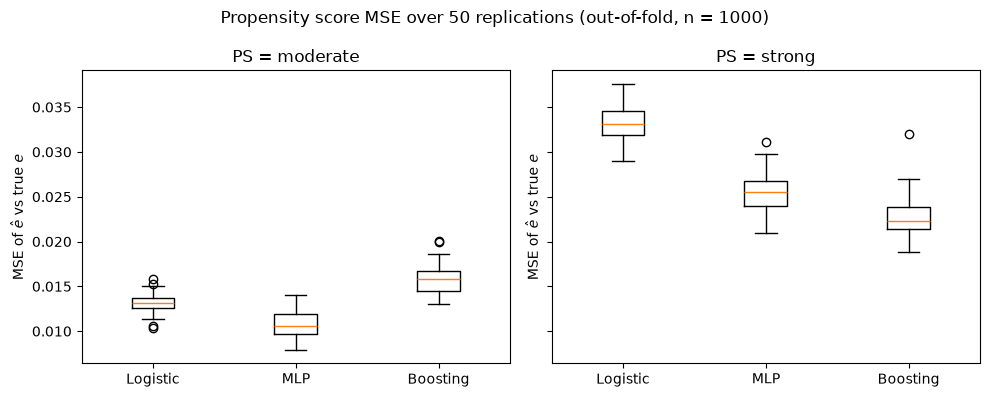

In [11]:
LABEL = {"logistic": "Logistic", "mlp": "MLP", "gbm": "Boosting"}

# (a) MSE across replications
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, ps in zip(axes, PS_SCENARIOS):
    sub = metrics[metrics.ps == ps]
    ax.boxplot([sub[sub.model == m]["mse"] for m in MODELS])
    ax.set_xticks(range(1, len(MODELS) + 1), [LABEL[m] for m in MODELS])
    ax.set_title(f"PS = {ps}")
    ax.set_ylabel("MSE of $\\hat e$ vs true $e$")
fig.suptitle(f"Propensity score MSE over {R} replications (out-of-fold, n = {N})")
fig.tight_layout()
fig.savefig(RES_DIR / "fig_part1_mse_boxplot.png", dpi=150)
plt.show()

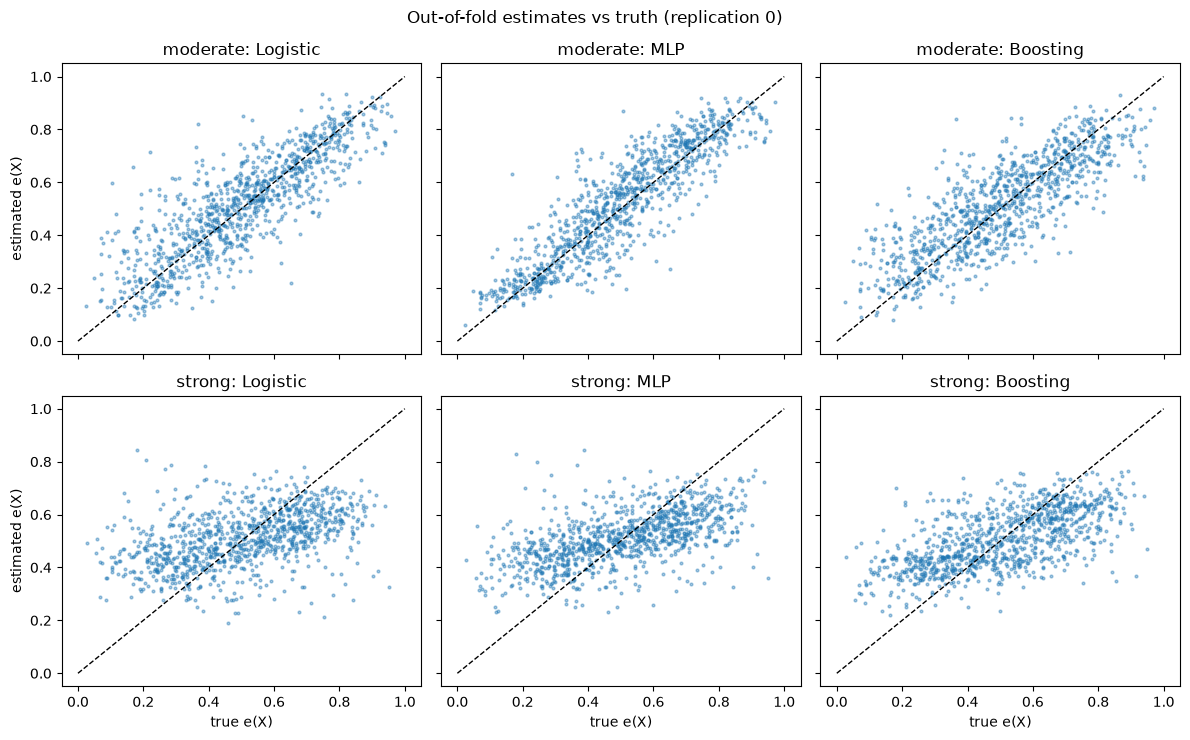

In [12]:
# (b) Estimated vs true propensity score, one replication
r_show = 0
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), sharex=True, sharey=True)
for i, ps in enumerate(PS_SCENARIOS):
    e_true = load_setting(ps)["e"][r_show]
    for j, m in enumerate(MODELS):
        ax = axes[i, j]
        ax.scatter(e_true, EHAT[ps][f"ehat_{m}"][r_show], s=4, alpha=.4)
        ax.plot([0, 1], [0, 1], "k--", lw=1)
        ax.set_title(f"{ps}: {LABEL[m]}")
        if i == 1: ax.set_xlabel("true e(X)")
        if j == 0: ax.set_ylabel("estimated e(X)")
fig.suptitle(f"Out-of-fold estimates vs truth (replication {r_show})")
fig.tight_layout()
fig.savefig(RES_DIR / "fig_part1_scatter.png", dpi=150)
plt.show()

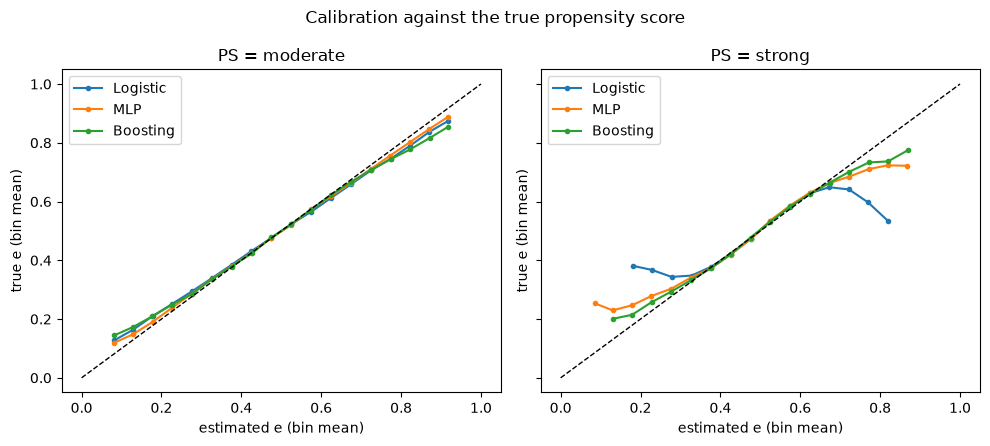

In [13]:
# (c) Calibration against the truth, pooled over all replications:
#     bin units by estimated e, plot mean estimate vs mean true e in each bin
bins = np.linspace(0, 1, 21)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, ps in zip(axes, PS_SCENARIOS):
    e_true = load_setting(ps)["e"][:R].ravel()
    for m in MODELS:
        eh = EHAT[ps][f"ehat_{m}"].ravel()
        idx = np.digitize(eh, bins) - 1
        ok = [b for b in range(len(bins) - 1) if (idx == b).sum() >= 50]
        ax.plot([eh[idx == b].mean() for b in ok], [e_true[idx == b].mean() for b in ok],
                "o-", ms=3, label=LABEL[m])
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"PS = {ps}")
    ax.set_xlabel("estimated e (bin mean)")
    ax.set_ylabel("true e (bin mean)")
    ax.legend()
fig.suptitle("Calibration against the true propensity score")
fig.tight_layout()
fig.savefig(RES_DIR / "fig_part1_calibration.png", dpi=150)
plt.show()

## 7. What Part 2 needs

`results/ehat_{ps}.npz` holds the out-of-fold $\hat e$ for every model and replication, in the same row order as `sim_data/train_{ps}_good_n1000.npz`. Part 2 combines the two files:

```python
d  = np.load("sim_data/train_strong_good_n1000.npz")   # X, A, Y, e (true), ...
eh = np.load("results/ehat_strong.npz")                 # ehat_logistic, ehat_mlp, ehat_gbm, folds
r = 0
A, Y = d["A"][r], d["Y"][r]
e_hat = eh["ehat_mlp"][r]        # plug into the IPW estimator
```